# MMA3001 Project - Ellena Glenk

## Setup and Import
This block needs to be run at the beginning of each runtime.

### Install Libraries

In [9]:
# Install libraries
!pip install -q open3d

# Standard Python libraries
import os
import re
import zipfile
import shutil
import subprocess
from pathlib import Path
from collections import defaultdict

# Numerical/data libraries
import numpy as np
import pandas as pd

# Image processing
from PIL import Image
import matplotlib.pyplot as plt

# Machine learning
from sklearn.model_selection import train_test_split

# 3D processing
import open3d as o3d

# Display plots inside the notebook
%matplotlib inline

import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from PIL import Image

# GitHub
from google.colab import userdata
from google.colab import drive
import tempfile
import shutil

print("Libraries loaded successfully.")

Libraries loaded successfully.


### Setup GitHub

In [2]:
# ============================================================
# GITHUB CONFIGURATION
# ============================================================

# Replace these with your GitHub details
GITHUB_USERNAME = "ellenaglenk"
GITHUB_REPO = "MMA3001_Project_34957189"

# Use the same email associated with your GitHub account
GITHUB_EMAIL = "egle0003@student.monash.edu"

# Configure Git author information
subprocess.run(
    ["git", "config", "--global", "user.name", GITHUB_USERNAME],
    check=True
)

subprocess.run(
    ["git", "config", "--global", "user.email", GITHUB_EMAIL],
    check=True
)

# Repository directory in Colab
REPO_DIR = Path("/content") / GITHUB_REPO

print("Git configuration complete!")
print("Repository directory:", REPO_DIR)

Git configuration complete!
Repository directory: /content/MMA3001_Project_34957189


In [3]:
# ============================================================
# CONNECT COLAB TO GITHUB
# ============================================================

# Retrieve the token securely from Colab Secrets
github_token = userdata.get("GITHUB_TOKEN")

if not github_token:
    raise ValueError("GITHUB_TOKEN was not found in Colab Secrets.")

# Git authentication without including the token in the URL
askpass_dir = tempfile.TemporaryDirectory()
askpass_path = Path(askpass_dir.name) / "git_askpass.sh"

askpass_path.write_text(
    '#!/bin/sh\n'
    'case "$1" in\n'
    '  *Username*) printf "%s\\n" "x-access-token" ;;\n'
    '  *Password*) printf "%s\\n" "$GITHUB_TOKEN" ;;\n'
    'esac\n'
)

askpass_path.chmod(0o700)

git_env = os.environ.copy()
git_env["GITHUB_TOKEN"] = github_token
git_env["GIT_ASKPASS"] = str(askpass_path)
git_env["GIT_TERMINAL_PROMPT"] = "0"

# Clone the repository if it is not already present
repo_url = (
    f"https://github.com/{GITHUB_USERNAME}/{GITHUB_REPO}.git"
)

if not (REPO_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", repo_url, str(REPO_DIR)],
        check=True,
        env=git_env
    )

print("GitHub repository connected!")
print("Local repository:", REPO_DIR)

GitHub repository connected!
Local repository: /content/MMA3001_Project_34957189


In [8]:
# ============================================================
# LOCATE NOTEBOOK IN GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

# Change this if your notebook is in a Drive subfolder
NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/MMA3001_Assignment.ipynb"
)

print("Notebook found:", NOTEBOOK_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Notebook found: True


In [10]:
# ============================================================
# SAVE AND COMMIT NOTEBOOK TO GITHUB
# ============================================================

def commit_to_github(message):
    """
    Commit the latest saved Colab notebook to GitHub.

    Parameters
    ----------
    message : str
        A description of the changes being committed.
    """

    # Check that the notebook exists in Google Drive
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            f"Notebook not found: {NOTEBOOK_PATH}"
        )

    # Copy the notebook into the GitHub repository
    destination = REPO_DIR / NOTEBOOK_PATH.name

    shutil.copy2(NOTEBOOK_PATH, destination)

    # Stage only the notebook (not the dataset or secrets)
    subprocess.run(
        ["git", "add", "--", destination.name],
        cwd=REPO_DIR,
        check=True
    )

    # Check whether there are changes to commit
    changes = subprocess.run(
        ["git", "diff", "--cached", "--quiet"],
        cwd=REPO_DIR
    )

    if changes.returncode == 0:
        print("No new changes to commit.")
        return

    if changes.returncode != 1:
        raise RuntimeError("Unable to check staged changes.")

    # Create a Git commit
    subprocess.run(
        ["git", "commit", "-m", message],
        cwd=REPO_DIR,
        check=True
    )

    # Push changes to GitHub
    subprocess.run(
        ["git", "push", "origin", "HEAD"],
        cwd=REPO_DIR,
        env=git_env,
        check=True
    )

    print("Successfully committed and pushed to GitHub!")
    print("Commit message:", message)

In [ ]:
# ============================================================
# SAVE AND COMMIT NOTEBOOK TO GITHUB
# ============================================================

commit_to_github("Completed setup and GitHub")

### Upload Zip File from Connected Google Drive

In [28]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

print("Google Drive connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!


In [29]:
from pathlib import Path

# Google Drive ZIP path
zip_path = Path(
    "/content/drive/MyDrive/2026/Tree_Dataset_SummerGT.zip"
)

# Check that the file exists
if not zip_path.is_file():
    raise FileNotFoundError(
        f"ZIP file not found: {zip_path}"
    )

print("Dataset found successfully!")
print("File:", zip_path.name)
print("Size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")

Dataset found successfully!
File: Tree_Dataset_SummerGT.zip
Size: 735.57 MB


### Extract the ZIP File

In [30]:
import zipfile
from pathlib import Path

# Location of your ZIP file in Google Drive
zip_path = Path("/content/drive/MyDrive/2026/Tree_Dataset_SummerGT.zip")

# Location where the extracted images will be stored
dataset_dir = Path("/content/tree_dataset")

# Check that the ZIP file exists
if not zip_path.exists():
    raise FileNotFoundError(
        f"ZIP file not found: {zip_path}\n"
        "Make sure Google Drive is mounted."
    )

# Create extraction folder
dataset_dir.mkdir(parents=True, exist_ok=True)

# Check whether the ZIP file is valid
if not zipfile.is_zipfile(zip_path):
    raise ValueError("The selected file is not a valid ZIP archive.")

# Extract all files
print("Extracting dataset. This may take a few minutes...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_dir)

print("Dataset extracted successfully!")
print("Extracted to:", dataset_dir)

Extracting dataset. This may take a few minutes...
Dataset extracted successfully!
Extracted to: /content/tree_dataset


## Inspect Images and their Format
This block was used to view and analyse images. It does not need to be run at the start of each runtime.

### Check Extracted Images

In [13]:
image_extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

image_files = [
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_files))

print("\nFirst 20 filenames:")
for path in image_files[:20]:
    print(path.name)

Total images found: 2810

First 20 filenames:
R15N23_Winter_RGB-13-06-09.png
R07N01_Summer_D-13-20-46.png
R11N01_Summer_D-13-41-4.png
R12N01_Summer_D-13-45-28.png
R08N12_Winter_RGB-12-02-24.png
R15N16_Summer_GT-14-3-57.png
R08N01_Winter_D-12-01-11.png
R07N03_Winter_RGB-11-57-09.png
R13N06_Winter_D-12-55-27.png
R15N18_Summer_D-14-4-10.png
R17N04_Summer_GT-14-10-32.png
R11N05_Winter_D-12-14-33.png
R11N15_Summer_RGB-13-42-22.png
R03N03_Summer_GT-12-57-4.png
R01N26_Winter_RGB-11-26-00.png
R15N24_Winter_RGB-13-06-11.png
R07N12_Summer_D-13-21-55.png
R12N30_Winter_D-12-52-46.png
R02N01_Summer_GT-12-49-15.png
R15N21_Summer_RGB-14-4-19.png


### Inspect Dataset

In [14]:
# Inspect filenames
image_extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

image_files = [
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print(f"Total image files found: {len(image_files)}")

# Print the first 30 filenames
for path in image_files[:30]:
    print(path.name)



# Inspect and show directories containing data
directories = sorted(set(path.parent for path in image_files))

print(f"Number of image directories: {len(directories)}")

for directory in directories[:30]:
    print(directory)

Total image files found: 2810
R15N23_Winter_RGB-13-06-09.png
R07N01_Summer_D-13-20-46.png
R11N01_Summer_D-13-41-4.png
R12N01_Summer_D-13-45-28.png
R08N12_Winter_RGB-12-02-24.png
R15N16_Summer_GT-14-3-57.png
R08N01_Winter_D-12-01-11.png
R07N03_Winter_RGB-11-57-09.png
R13N06_Winter_D-12-55-27.png
R15N18_Summer_D-14-4-10.png
R17N04_Summer_GT-14-10-32.png
R11N05_Winter_D-12-14-33.png
R11N15_Summer_RGB-13-42-22.png
R03N03_Summer_GT-12-57-4.png
R01N26_Winter_RGB-11-26-00.png
R15N24_Winter_RGB-13-06-11.png
R07N12_Summer_D-13-21-55.png
R12N30_Winter_D-12-52-46.png
R02N01_Summer_GT-12-49-15.png
R15N21_Summer_RGB-14-4-19.png
R03N34_Winter_D-11-39-13.png
R10N07_Summer_RGB-13-36-34.png
R10N01_Summer_D-13-36-11.png
R16N17_Summer_RGB-14-7-58.png
R01N18_Summer_D-12-43-21.png
R17N13_Summer_D-14-11-31.png
R13N25_Summer_GT-13-51-34.png
R13N08_Summer_D-13-50-9.png
R07N08_Winter_D-11-57-35.png
R05N11_Winter_D-11-47-42.png
Number of image directories: 1
/content/tree_dataset/Dataset (With Summer GT)


### Inspect Image Dimensions and Pixel Values

In [15]:
def inspect_image(path):
    """
    Print basic information about an image.

    Parameters
    ----------
    path : Path
        Path to the image.
    """

    image = Image.open(path)
    array = np.array(image)

    print(f"\nFile: {path.name}")
    print(f"Format: {image.format}")
    print(f"Mode: {image.mode}")
    print(f"Size: {image.size}")
    print(f"Array shape: {array.shape}")
    print(f"Data type: {array.dtype}")
    print(f"Minimum pixel value: {array.min()}")
    print(f"Maximum pixel value: {array.max()}")


# Inspect the first few images
for path in image_files[:10]:
    inspect_image(path)


File: R15N23_Winter_RGB-13-06-09.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 5
Maximum pixel value: 255

File: R07N01_Summer_D-13-20-46.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 164

File: R11N01_Summer_D-13-41-4.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 144

File: R12N01_Summer_D-13-45-28.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 164

File: R08N12_Winter_RGB-12-02-24.png
Format: PNG
Mode: RGB
Size: (640, 480)
Array shape: (480, 640, 3)
Data type: uint8
Minimum pixel value: 1
Maximum pixel value: 255

File: R15N16_Summer_GT-14-3-57.png
Format: PNG
Mode: L
Size: (256, 256)
Array shape: (256, 256)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


### Check Image Types, Pairs, Types etc

In [16]:
from pathlib import Path

# image_files was created in Step 6

rgb_files = []
depth_files = []
gt_files = []

for path in image_files:

    name = path.name.upper()

    if "_RGB-" in name:
        rgb_files.append(path)

    elif "_D-" in name:
        depth_files.append(path)

    elif "_GT-" in name:
        gt_files.append(path)

print("Dataset summary")
print("-------------------------")
print("RGB images:", len(rgb_files))
print("Depth images:", len(depth_files))
print("Ground truth images:", len(gt_files))

print("\nTotal classified:",
      len(rgb_files) + len(depth_files) + len(gt_files))

Dataset summary
-------------------------
RGB images: 1124
Depth images: 1124
Ground truth images: 562

Total classified: 2810


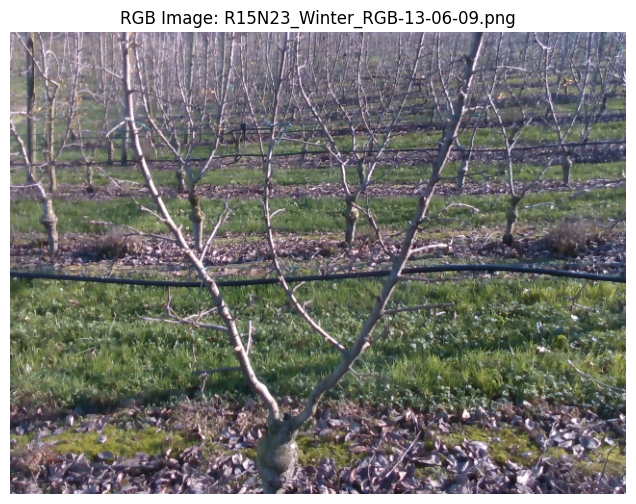

In [17]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Select the first RGB image
rgb_path = rgb_files[0]

rgb = np.array(Image.open(rgb_path))

plt.figure(figsize=(10, 6))

plt.imshow(rgb)

plt.title(f"RGB Image: {rgb_path.name}")
plt.axis("off")

plt.show()

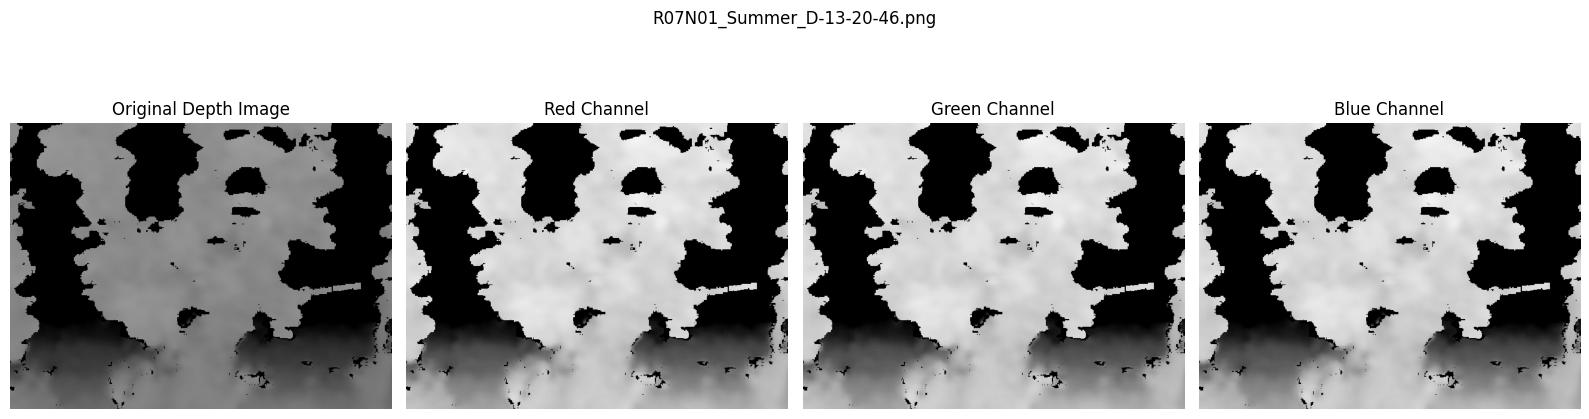

In [18]:
depth_path = depth_files[0]

depth = np.array(Image.open(depth_path))

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

# Original depth image
axes[0].imshow(depth)
axes[0].set_title("Original Depth Image")

# Individual colour channels
channels = ["Red", "Green", "Blue"]

for i in range(3):

    axes[i + 1].imshow(
        depth[:, :, i],
        cmap="gray"
    )

    axes[i + 1].set_title(f"{channels[i]} Channel")

for ax in axes:
    ax.axis("off")

plt.suptitle(depth_path.name)
plt.tight_layout()
plt.show()

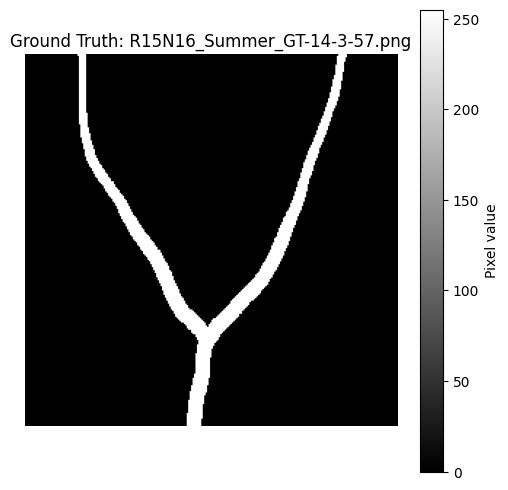

Image shape: (256, 256)
Unique pixel values: [  0 255]


In [19]:
gt_path = gt_files[0]

gt = np.array(Image.open(gt_path))

plt.figure(figsize=(6, 6))

plt.imshow(gt, cmap="gray", vmin=0, vmax=255)

plt.colorbar(label="Pixel value")

plt.title(f"Ground Truth: {gt_path.name}")
plt.axis("off")

plt.show()

print("Image shape:", gt.shape)
print("Unique pixel values:", np.unique(gt)[:30])

In [20]:
def get_observation_id(path):
    """
    Extract a common observation identifier by removing
    the RGB, D or GT label from the filename.
    """

    name = path.stem

    for label in ["_RGB-", "_D-", "_GT-"]:
        if label in name:
            return name.replace(label, "_")

    return None


# Create dictionaries of images
rgb_dict = {
    get_observation_id(p): p for p in rgb_files
}

depth_dict = {
    get_observation_id(p): p for p in depth_files
}

gt_dict = {
    get_observation_id(p): p for p in gt_files
}

# Find matching observations
rgb_depth_pairs = set(rgb_dict) & set(depth_dict)

complete_sets = (
    set(rgb_dict) &
    set(depth_dict) &
    set(gt_dict)
)

print("Matching RGB-depth pairs:", len(rgb_depth_pairs))
print("Complete RGB-depth-GT sets:", len(complete_sets))

Matching RGB-depth pairs: 1124
Complete RGB-depth-GT sets: 562


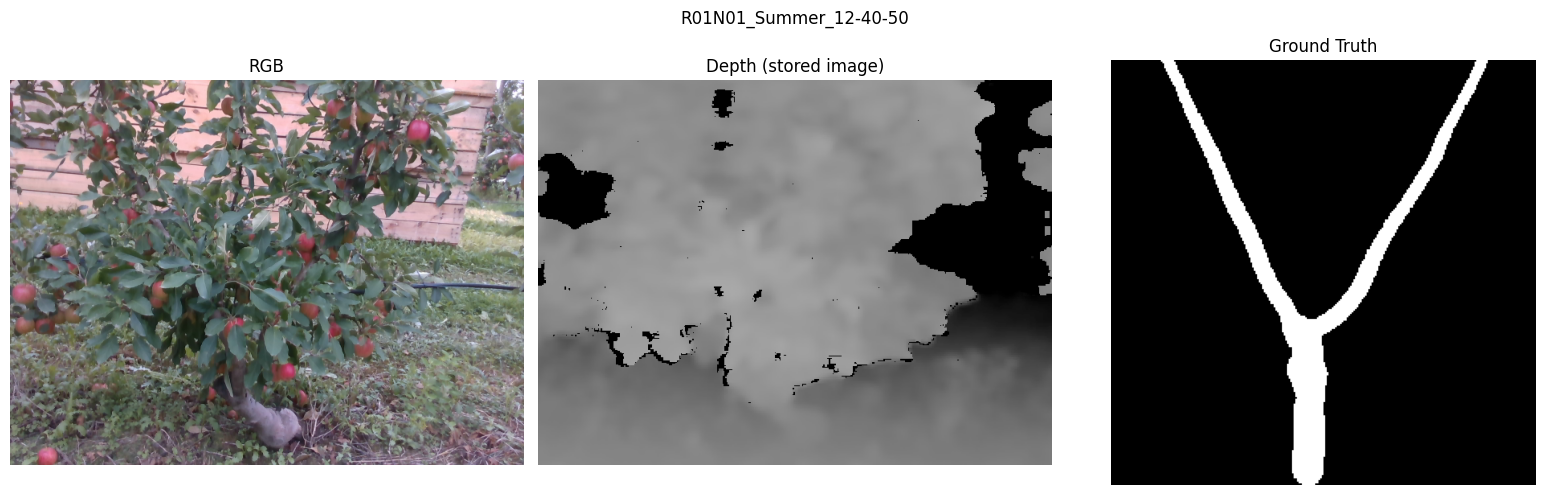

In [21]:
if len(complete_sets) > 0:

    observation = sorted(complete_sets)[0]

    rgb = np.array(Image.open(rgb_dict[observation]))
    depth = np.array(Image.open(depth_dict[observation]))
    gt = np.array(Image.open(gt_dict[observation]))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].imshow(rgb)
    axes[0].set_title("RGB")

    axes[1].imshow(depth)
    axes[1].set_title("Depth (stored image)")

    axes[2].imshow(gt, cmap="gray")
    axes[2].set_title("Ground Truth")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(observation)
    plt.tight_layout()
    plt.show()

else:
    print("No complete RGB-depth-GT sets found.")
    print("The images may use different timestamps or naming conventions.")

In [22]:
import numpy as np
from PIL import Image

depth = np.array(Image.open(depth_files[0]))

# Compare the three channels
red = depth[:, :, 0]
green = depth[:, :, 1]
blue = depth[:, :, 2]

print("Red = Green:", np.array_equal(red, green))
print("Green = Blue:", np.array_equal(green, blue))

print("\nDepth values:")
print("Minimum:", depth.min())
print("Maximum:", depth.max())
print("Unique values:", len(np.unique(depth)))

Red = Green: True
Green = Blue: True

Depth values:
Minimum: 0
Maximum: 164
Unique values: 151


### Dataset Table

In [23]:
import pandas as pd
import re

records = []

# Loop through all observations with matching RGB and depth
for observation in sorted(rgb_depth_pairs):

    # Extract tree identifier and season
    match = re.match(
        r"(R\d+N\d+)_(Summer|Winter)_(.+)",
        observation,
        re.IGNORECASE
    )

    if match is None:
        print("Unrecognised filename:", observation)
        continue

    tree_id = match.group(1)
    season = match.group(2)
    timestamp = match.group(3)

    # Check whether a GT image exists
    has_gt = observation in gt_dict

    records.append({
        "observation_id": observation,
        "tree_id": tree_id,
        "season": season,
        "timestamp": timestamp,
        "rgb_path": str(rgb_dict[observation]),
        "depth_path": str(depth_dict[observation]),
        "gt_path": str(gt_dict[observation]) if has_gt else None,
        "has_gt": has_gt
    })

dataset = pd.DataFrame(records)

print("Dataset created successfully!")
print("Total observations:", len(dataset))
print("Unique trees:", dataset["tree_id"].nunique())

display(dataset.head())

# Save the table
dataset.to_csv(
    "/content/tree_dataset_metadata.csv",
    index=False
)

Dataset created successfully!
Total observations: 1124
Unique trees: 562


,observation_id,tree_id,season,timestamp,rgb_path,depth_path,gt_path,has_gt
0,R01N01_Summer_12-40-50,R01N01,Summer,12-40-50,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,True
1,R01N01_Winter_11-23-49,R01N01,Winter,11-23-49,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,None,False
2,R01N02_Summer_12-40-59,R01N02,Summer,12-40-59,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,True
3,R01N02_Winter_11-23-52,R01N02,Winter,11-23-52,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,None,False
4,R01N03_Summer_12-41-4,R01N03,Summer,12-41-4,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,/content/tree_dataset/Dataset (With Summer GT)...,True


## Seperate Training and Validation Data
This block needs to be run at the begining of each runtime.

### Split data 80/20

In [31]:
# Identify each unique physical tree
unique_trees = dataset["tree_id"].unique()

# Split trees into 80% training and 20% validation
train_trees, validation_trees = train_test_split(
    unique_trees,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# Select all observations belonging to training trees
train_data = dataset[
    dataset["tree_id"].isin(train_trees)
].copy()

# Select all observations belonging to validation trees
validation_data = dataset[
    dataset["tree_id"].isin(validation_trees)
].copy()

# Check that no tree appears in both datasets
overlap = set(train_trees) & set(validation_trees)

assert len(overlap) == 0, "Data leakage detected!"

print("Training and validation split successful!")
print("-----------------------------------------")

print("Training trees:", len(train_trees))
print("Validation trees:", len(validation_trees))

print("\nTraining observations:", len(train_data))
print("Validation observations:", len(validation_data))

print("\nOverlapping trees:", len(overlap))

Training and validation split successful!
-----------------------------------------
Training trees: 449
Validation trees: 113

Training observations: 898
Validation observations: 226

Overlapping trees: 0


### Check Ground Truth Distribution

In [32]:
print("Training dataset")
print("----------------")

print("Total observations:", len(train_data))
print("With ground truth:", train_data["has_gt"].sum())
print("Without ground truth:", (~train_data["has_gt"]).sum())

print("\nValidation dataset")
print("------------------")

print("Total observations:", len(validation_data))
print("With ground truth:", validation_data["has_gt"].sum())
print("Without ground truth:", (~validation_data["has_gt"]).sum())

# Check observations by season
print("\nTraining observations by season:")
print(train_data.groupby("season").size())

print("\nValidation observations by season:")
print(validation_data.groupby("season").size())

Training dataset
----------------
Total observations: 898
With ground truth: 449
Without ground truth: 449

Validation dataset
------------------
Total observations: 226
With ground truth: 113
Without ground truth: 113

Training observations by season:
season
Summer    449
Winter    449
dtype: int64

Validation observations by season:
season
Summer    113
Winter    113
dtype: int64


### Save Datasets

In [33]:
from pathlib import Path

# Create folder for processed data
processed_dir = Path("/content/processed_data")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save training metadata
train_data.to_csv(
    processed_dir / "train_metadata.csv",
    index=False
)

# Save validation metadata
validation_data.to_csv(
    processed_dir / "validation_metadata.csv",
    index=False
)

print("Dataset metadata saved successfully!")
print("Location:", processed_dir)

Dataset metadata saved successfully!
Location: /content/processed_data


## 2D Interpolation of Depth Images

### Inspect depth image values

Observation: R01N01_Summer_12-40-50
Depth image shape: (480, 640)
Minimum value: 0
Maximum value: 169
Unique values: 157
Zero-valued pixels: 36359
Percentage of zeros: 11.84 %


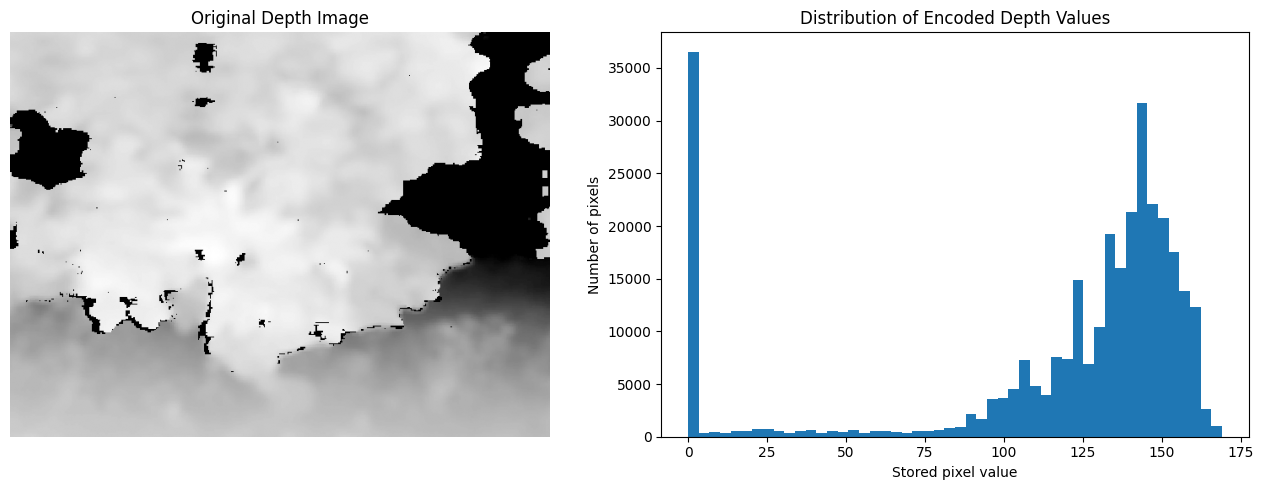

In [34]:
# Select a summer observation from the training dataset
example = train_data[
    (train_data["season"] == "Summer") &
    (train_data["has_gt"])
].iloc[0]

# Load the depth image
depth_image = Image.open(example["depth_path"]).convert("RGB")

# The three channels are identical, so use the first channel
depth = np.asarray(depth_image)[:, :, 0]

# Calculate basic statistics
print("Observation:", example["observation_id"])
print("Depth image shape:", depth.shape)
print("Minimum value:", depth.min())
print("Maximum value:", depth.max())
print("Unique values:", len(np.unique(depth)))
print("Zero-valued pixels:", np.sum(depth == 0))
print("Percentage of zeros:", round(np.mean(depth == 0) * 100, 2), "%")

# Display the depth image and its value distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(depth, cmap="gray")
axes[0].set_title("Original Depth Image")
axes[0].axis("off")

axes[1].hist(depth.ravel(), bins=50)
axes[1].set_title("Distribution of Encoded Depth Values")
axes[1].set_xlabel("Stored pixel value")
axes[1].set_ylabel("Number of pixels")

plt.tight_layout()
plt.show()

STEP 11.2 - INTERPOLATION RESULTS
--------------------------------
Candidate valid pixels: 22410
Training pixels: 20169
Withheld test pixels: 2241
Linear coverage: 100.0 %

Nearest-neighbour RMSE (all test points): 0.6653
Nearest-neighbour RMSE (common points): 0.6653
Linear RMSE (common points): 0.4088


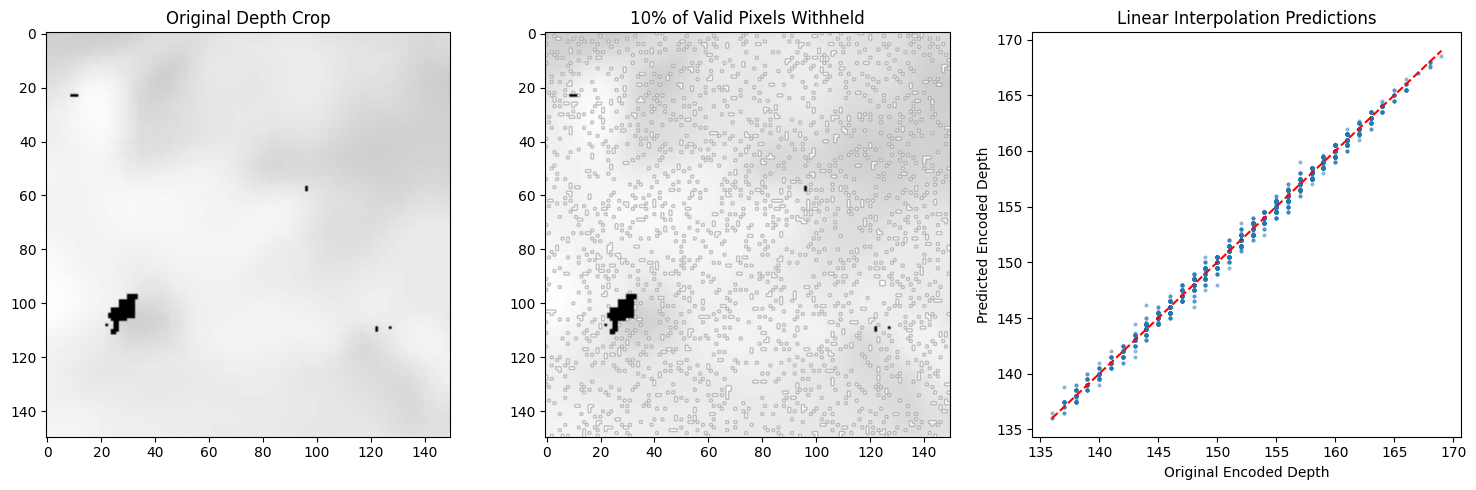

In [35]:

# Use the depth image loaded in Step 11.1
depth_float = depth.astype(np.float32)

# Select a central region to keep computation manageable
height, width = depth_float.shape

crop_size = 150

y_start = (height - crop_size) // 2
x_start = (width - crop_size) // 2

depth_crop = depth_float[
    y_start:y_start + crop_size,
    x_start:x_start + crop_size
]

# Identify nonzero pixels as candidate valid measurements
# Note: This is a working assumption for this experiment.
valid_mask = depth_crop > 0

# Create coordinate grids
yy, xx = np.indices(depth_crop.shape)

# Extract coordinates and values of candidate valid pixels
valid_points = np.column_stack((
    xx[valid_mask],
    yy[valid_mask]
))

valid_values = depth_crop[valid_mask]

# Randomly withhold 10% of the candidate valid measurements
rng = np.random.default_rng(42)

indices = rng.permutation(len(valid_values))

n_test = int(0.10 * len(valid_values))

test_indices = indices[:n_test]
train_indices = indices[n_test:]

# Known points used for interpolation
train_points = valid_points[train_indices]
train_values = valid_values[train_indices]

# Hidden points used for validation
test_points = valid_points[test_indices]
test_values = valid_values[test_indices]

# ------------------------------------------------------------
# Nearest-neighbour interpolation
# ------------------------------------------------------------

nearest_predictions = griddata(
    train_points,
    train_values,
    test_points,
    method="nearest"
)

# ------------------------------------------------------------
# Linear interpolation
# ------------------------------------------------------------

linear_predictions = griddata(
    train_points,
    train_values,
    test_points,
    method="linear"
)

# Linear interpolation may return NaN outside the convex hull
linear_valid = np.isfinite(linear_predictions)

# Calculate RMSE for each method
nearest_rmse = np.sqrt(
    mean_squared_error(test_values, nearest_predictions)
)

linear_rmse = np.sqrt(
    mean_squared_error(
        test_values[linear_valid],
        linear_predictions[linear_valid]
    )
) if np.any(linear_valid) else np.nan

# Compare methods on the same points for fairness
common_mask = linear_valid & np.isfinite(nearest_predictions)

nearest_common_rmse = np.sqrt(
    mean_squared_error(
        test_values[common_mask],
        nearest_predictions[common_mask]
    )
) if np.any(common_mask) else np.nan

linear_common_rmse = np.sqrt(
    mean_squared_error(
        test_values[common_mask],
        linear_predictions[common_mask]
    )
) if np.any(common_mask) else np.nan

# Display results
print("INTERPOLATION RESULTS")
print("--------------------------------")
print("Candidate valid pixels:", len(valid_values))
print("Training pixels:", len(train_values))
print("Withheld test pixels:", len(test_values))
print("Linear coverage:", round(linear_valid.mean() * 100, 2), "%")
print()
print("Nearest-neighbour RMSE (all test points):", round(nearest_rmse, 4))
print("Nearest-neighbour RMSE (common points):", round(nearest_common_rmse, 4))
print("Linear RMSE (common points):", round(linear_common_rmse, 4))

# ------------------------------------------------------------
# Visualise withheld pixels and interpolation errors
# ------------------------------------------------------------

masked_crop = depth_crop.copy()

# Mark withheld measurements as missing for display
masked_crop[
    test_points[:, 1],
    test_points[:, 0]
] = np.nan

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(depth_crop, cmap="gray")
axes[0].set_title("Original Depth Crop")

axes[1].imshow(masked_crop, cmap="gray")
axes[1].set_title("10% of Valid Pixels Withheld")

axes[2].scatter(
    test_values[common_mask],
    linear_predictions[common_mask],
    s=4,
    alpha=0.4
)

axes[2].plot(
    [test_values.min(), test_values.max()],
    [test_values.min(), test_values.max()],
    "r--"
)

axes[2].set_title("Linear Interpolation Predictions")
axes[2].set_xlabel("Original Encoded Depth")
axes[2].set_ylabel("Predicted Encoded Depth")

plt.tight_layout()
plt.show()

### Once linear interpolation found with lower RMSE, text with more real world data

STEP 11.3 - MISSING PATCH INTERPOLATION
--------------------------------------
Patch size: 5 x 5
Patches created: 20
Pixels withheld: 500
Common valid predictions: 500

Nearest-neighbour RMSE: 0.9445
Linear interpolation RMSE: 0.5397


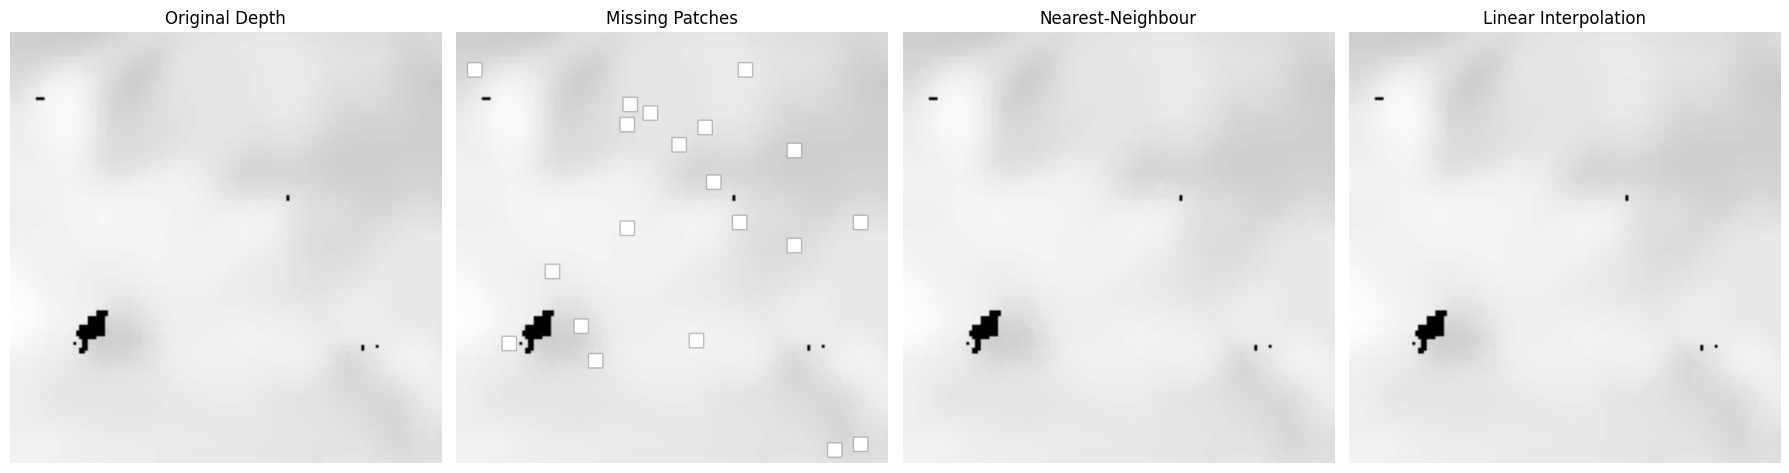

In [38]:
# Use the original depth crop from above
original = depth_crop.copy()

height, width = original.shape

# Create a reproducible random number generator
rng = np.random.default_rng(42)

# Define size and number of missing patches
patch_size = 5
num_patches = 20

# Identify candidate valid pixels
valid_mask = original > 0

# Create a mask identifying pixels to withhold
missing_mask = np.zeros(original.shape, dtype=bool)

# Select patches containing only nonzero measurements
candidate_patches = []

for y in range(height - patch_size + 1):
    for x in range(width - patch_size + 1):

        patch = valid_mask[
            y:y + patch_size,
            x:x + patch_size
        ]

        if np.all(patch):
            candidate_patches.append((y, x))

# Randomise candidate patch locations
rng.shuffle(candidate_patches)

patches_added = 0

for y, x in candidate_patches:

    # Prevent patches from overlapping
    if np.any(
        missing_mask[
            y:y + patch_size,
            x:x + patch_size
        ]
    ):
        continue

    missing_mask[
        y:y + patch_size,
        x:x + patch_size
    ] = True

    patches_added += 1

    if patches_added >= num_patches:
        break

# Create a copy with missing patches
damaged = original.copy()
damaged[missing_mask] = np.nan

# ------------------------------------------------------------
# Prepare interpolation coordinates
# ------------------------------------------------------------

yy, xx = np.indices(original.shape)

# Known measurements exclude zero values and withheld pixels
known_mask = valid_mask & ~missing_mask

known_points = np.column_stack((
    xx[known_mask],
    yy[known_mask]
))

known_values = original[known_mask]

# Locations of missing patches
missing_points = np.column_stack((
    xx[missing_mask],
    yy[missing_mask]
))

true_values = original[missing_mask]

# ------------------------------------------------------------
# Nearest-neighbour interpolation
# ------------------------------------------------------------

nearest_values = griddata(
    known_points,
    known_values,
    missing_points,
    method="nearest"
)

# ------------------------------------------------------------
# Linear interpolation
# ------------------------------------------------------------

linear_values = griddata(
    known_points,
    known_values,
    missing_points,
    method="linear"
)

# Only compare points where both methods return a value
common_mask = (
    np.isfinite(nearest_values) &
    np.isfinite(linear_values)
)

# Calculate RMSE
nearest_rmse = np.sqrt(
    mean_squared_error(
        true_values[common_mask],
        nearest_values[common_mask]
    )
)

linear_rmse = np.sqrt(
    mean_squared_error(
        true_values[common_mask],
        linear_values[common_mask]
    )
)

# ------------------------------------------------------------
# Reconstruct the images
# ------------------------------------------------------------

nearest_reconstruction = damaged.copy()
linear_reconstruction = damaged.copy()

nearest_reconstruction[
    missing_points[:, 1],
    missing_points[:, 0]
] = nearest_values

linear_reconstruction[
    missing_points[:, 1],
    missing_points[:, 0]
] = linear_values

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("MISSING PATCH INTERPOLATION")
print("--------------------------------------")
print("Patch size:", patch_size, "x", patch_size)
print("Patches created:", patches_added)
print("Pixels withheld:", missing_mask.sum())
print("Common valid predictions:", common_mask.sum())
print()
print("Nearest-neighbour RMSE:", round(nearest_rmse, 4))
print("Linear interpolation RMSE:", round(linear_rmse, 4))

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

images = [
    original,
    damaged,
    nearest_reconstruction,
    linear_reconstruction
]

titles = [
    "Original Depth",
    "Missing Patches",
    "Nearest-Neighbour",
    "Linear Interpolation"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=170)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()